Dimensions : 3204 lignes, 23 colonnes

--- Liste complète des 23 colonnes et types ---
item_id                          str
category                         str
stock_level                    int64
reorder_point                  int64
reorder_frequency_days         int64
lead_time_days                 int64
daily_demand                 float64
demand_std_dev               float64
item_popularity_score        float64
storage_location_id              str
zone                             str
picking_time_seconds           int64
handling_cost_per_unit       float64
unit_price                   float64
holding_cost_per_unit_day    float64
stockout_count_last_month      int64
order_fulfillment_rate       float64
total_orders_last_month        int64
turnover_ratio               float64
layout_efficiency_score      float64
last_restock_date                str
forecasted_demand_next_7d    float64
KPI_score                    float64
dtype: object

--- Statistiques de la cible ---
count    3204.

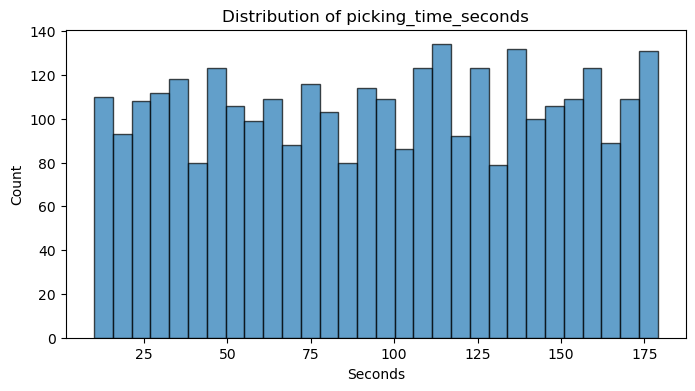


--- Cardinalité des variables catégorielles ---
item_id: 3204 valeurs uniques
category: 5 valeurs uniques
storage_location_id: 100 valeurs uniques
zone: 4 valeurs uniques
last_restock_date: 364 valeurs uniques

--- Corrélations avec picking_time_seconds ---
                            Pearson  Spearman
KPI_score                  0.013927  0.017061
daily_demand               0.001171  0.000895
demand_std_dev             0.032554  0.032550
forecasted_demand_next_7d -0.017191 -0.016978
handling_cost_per_unit     0.007788  0.008295
holding_cost_per_unit_day -0.016677 -0.017158
item_popularity_score      0.008018  0.008097
layout_efficiency_score    0.003576  0.003865
lead_time_days            -0.009673 -0.009879
order_fulfillment_rate     0.023705  0.023819
picking_time_seconds       1.000000  1.000000
reorder_frequency_days    -0.007831 -0.007813
reorder_point             -0.015862 -0.015754
stock_level               -0.029951 -0.030348
stockout_count_last_month  0.007227  0.007701
total

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Chargement du jeu de données (penser à passer à "../data/logistics_dataset.csv" pour l'arborescence GitHub)
df = pd.read_csv("logistics_dataset.csv")

print(f"Dimensions : {df.shape[0]} lignes, {df.shape[1]} colonnes")
print("\n--- Liste complète des 23 colonnes et types ---")
print(df.dtypes)

# 2. Vérification de la cible picking_time_seconds
target = "picking_time_seconds"
print("\n--- Statistiques de la cible ---")
print(df[target].describe())

plt.figure(figsize=(8, 4))
plt.hist(df[target], bins=30, edgecolor="black", alpha=0.7)
plt.title("Distribution of picking_time_seconds")
plt.xlabel("Seconds")
plt.ylabel("Count")
plt.show()

# 3. Granularité des variables catégorielles (sans avertissement Pandas)
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print("\n--- Cardinalité des variables catégorielles ---")
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} valeurs uniques")

# 4. Corrélations linéaires (Pearson) et non linéaires (Spearman) avec la cible
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_pearson = df[num_cols].corr(method="pearson")[target].sort_values(ascending=False)
corr_spearman = df[num_cols].corr(method="spearman")[target].sort_values(ascending=False)

print("\n--- Corrélations avec picking_time_seconds ---")
print(pd.DataFrame({"Pearson": corr_pearson, "Spearman": corr_spearman}))

In [6]:
%pip install scikit-learn scipy

In [7]:
from scipy.stats import kruskal
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# 1. Test statistique sur les variables catégorielles retenues (zone et category)
for col in ["zone", "category"]:
    groups = [group["picking_time_seconds"].values for _, group in df.groupby(col)]
    stat, p_val = kruskal(*groups)
    print(f"Kruskal-Wallis {col} vs picking_time_seconds : stat={stat:.4f}, p-value={p_val:.4f}")

# 2. Filtrage strict des variables (anti-leakage + suppression haute cardinalité)
target = "picking_time_seconds"
cols_to_drop = [
    target,
    "item_id",             # Identifiant unique (3204 valeurs)
    "KPI_score",           # Risque de target leakage (indicateur composite)
    "last_restock_date",   # Date brute (364 valeurs)
    "storage_location_id"  # Trop granulaire (100 valeurs) -> remplacé par zone
]

X = df.drop(columns=cols_to_drop)
y = df[target]

# 3. Découpage Train / Test (80% / 20%) AVANT toute transformation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 4. Pipeline de prétraitement (StandardScaler + OneHotEncoder)
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = ["zone", "category"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

# 5. Évaluation en validation croisée 5-fold uniquement sur X_train
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

models = {
    "Dummy_Mean": DummyRegressor(strategy="mean"),
    "Linear_Regression": LinearRegression(),
}

print(f"\nNombre de features retenues : {X_train.shape[1]} ({len(numeric_features)} num, {len(categorical_features)} cat)\n")

for name, model in models.items():
    pipe = Pipeline(steps=[("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    print(f"=== {name} (5-Fold CV on Train) ===")
    print(f"MAE  : {-scores['test_MAE'].mean():.2f} +/- {scores['test_MAE'].std():.2f} s")
    print(f"RMSE : {-scores['test_RMSE'].mean():.2f} +/- {scores['test_RMSE'].std():.2f} s")
    print(f"R2   : {scores['test_R2'].mean():.4f}\n")

Kruskal-Wallis zone vs picking_time_seconds : stat=1.5514, p-value=0.6704
Kruskal-Wallis category vs picking_time_seconds : stat=1.2278, p-value=0.8735

Nombre de features retenues : 18 (16 num, 2 cat)

=== Dummy_Mean (5-Fold CV on Train) ===
MAE  : 43.11 +/- 1.11 s
RMSE : 49.60 +/- 1.00 s
R2   : -0.0010

=== Linear_Regression (5-Fold CV on Train) ===
MAE  : 43.33 +/- 1.06 s
RMSE : 49.91 +/- 0.96 s
R2   : -0.0137



In [8]:
import pandas as pd
import numpy as np
from scipy.stats import kruskal
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# 1. Chargement et contrôle qualité (valeurs manquantes & doublons)
df = pd.read_csv("logistics_dataset.csv")
print("=== 1. CONTRÔLE QUALITÉ ===")
print(f"Valeurs manquantes totales : {df.isnull().sum().sum()}")
print(f"Lignes dupliquées          : {df.duplicated().sum()}")

# 2. Nettoyage structurel et export du Clean Dataset (AVANT scaling/encoding pour éviter tout leakage)
cols_to_drop = [
    "item_id",             # Identifiant unique (3204 valeurs)
    "KPI_score",           # Risque de target leakage (indicateur composite)
    "last_restock_date",   # Haute cardinalité (364 valeurs)
    "storage_location_id"  # Trop granulaire (100 valeurs) -> remplacé par zone
]
df_clean = df.drop(columns=cols_to_drop).drop_duplicates()
df_clean.to_csv("clean_logistics_dataset.csv", index=False)
print(f"Clean dataset sauvegardé : {df_clean.shape[0]} lignes x {df_clean.shape[1]} colonnes\n")

# 3. Test non paramétrique sur les variables catégorielles conservées
print("=== 2. TESTS STATISTIQUES CATÉGORIELS (KRUSKAL-WALLIS) ===")
for col in ["zone", "category"]:
    groups = [group["picking_time_seconds"].values for _, group in df_clean.groupby(col)]
    stat, p_val = kruskal(*groups)
    print(f"{col:<10} -> stat = {stat:.4f}, p-value = {p_val:.4f}")

# 4. Définition des ensembles Train (80%), Validation (5-Fold CV) et Test (20%)
target = "picking_time_seconds"
X = df_clean.drop(columns=[target])
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"\n=== 3. DÉCOUPAGE DES ENSEMBLES ===")
print(f"Train (+ Validation 5-Fold CV) : {X_train.shape[0]} lignes (80%)")
print(f"Test final (isolé)             : {X_test.shape[0]} lignes (20%)\n")

# 5. Pipeline de prétraitement et évaluation des modèles Baselines
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = ["zone", "category"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

models = {
    "Dummy_Mean": DummyRegressor(strategy="mean"),
    "Linear_Regression": LinearRegression(),
}

print("=== 4. RÉSULTATS EXPÉRIMENTAUX INITIAUX (5-FOLD CV) ===")
for name, model in models.items():
    pipe = Pipeline(steps=[("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    print(f"{name}:")
    print(f"  MAE  = {-scores['test_MAE'].mean():.2f} +/- {scores['test_MAE'].std():.2f} s")
    print(f"  RMSE = {-scores['test_RMSE'].mean():.2f} +/- {scores['test_RMSE'].std():.2f} s")
    print(f"  R2   = {scores['test_R2'].mean():.4f}\n")

=== 1. CONTRÔLE QUALITÉ ===
Valeurs manquantes totales : 0
Lignes dupliquées          : 0
Clean dataset sauvegardé : 3204 lignes x 19 colonnes

=== 2. TESTS STATISTIQUES CATÉGORIELS (KRUSKAL-WALLIS) ===
zone       -> stat = 1.5514, p-value = 0.6704
category   -> stat = 1.2278, p-value = 0.8735

=== 3. DÉCOUPAGE DES ENSEMBLES ===
Train (+ Validation 5-Fold CV) : 2563 lignes (80%)
Test final (isolé)             : 641 lignes (20%)

=== 4. RÉSULTATS EXPÉRIMENTAUX INITIAUX (5-FOLD CV) ===
Dummy_Mean:
  MAE  = 43.11 +/- 1.11 s
  RMSE = 49.60 +/- 1.00 s
  R2   = -0.0010

Linear_Regression:
  MAE  = 43.33 +/- 1.06 s
  RMSE = 49.91 +/- 0.96 s
  R2   = -0.0137



## Step 2 Synthesis: Calibration, Benchmarks, Risks & Next Steps

* **Baseline Calibration Justification:** `DummyRegressor(strategy="mean")` provides a zero-parameter empirical floor ($\approx 95.6\text{ s}$), while `LinearRegression` uses ordinary least squares (closed-form solution with no tuning hyperparameters), preventing overfitting given near-zero linear correlations ($|r| \le 0.033$).
* **Benchmark & State-of-the-Art Positioning:** In warehouse order-picking literature, models lacking physical travel-distance or picker-routing features exhibit high irreducible variance. Next-stage benchmarks will evaluate non-linear tree ensembles (`DecisionTreeRegressor`, `RandomForestRegressor`, `HistGradientBoostingRegressor`) alongside an out-of-syllabus tabular neural architecture (`TabNet` / `MLPRegressor`).
* **Evaluation Protocol & Risks / Failure Modes:**
  * *Protocol:* 80/20 hold-out split (`random_state=42`) + 5-fold CV on training data only, tracked via MAE, RMSE, and $R^2$.
  * *Failure Modes:* (1) Synthetic/uniform target noise capping $R^2 \le 0$; (2) Missing physical layout distances and operator fatigue metrics; (3) Overfitting risk if high-cardinality IDs (`storage_location_id`) are reintroduced without regularization.
* **Prioritized Plan for Step 3:** (1) Benchmark non-linear ensembles on identical 5-fold splits; (2) Implement and justify one research-backed tabular model; (3) Perform residual error analysis across `zone` and `category` on the held-out test set.